# Tarea para el Hogar 04

##  1. Big Picture

LightGBM es el algoritmo estado del arte para datasets estructurados.
<br> La Bayesian Optimization es el estado del arte para optimización de hiperparámetros
<br> Las soluciones a las tres competencias de la asignatura contendrán LightGBMs y Bayesian Optimizations
<br> LightGBM ha aumentado en forma no darwiniana sus hiperparámetros en los últimos ocho años; no todos los existentes son útiles.
<br> Es necesario lograr entender cuales son los hiperparámetros relevantes de LightGBM

## 2. Hiperparámetros del LightGBM

Los objetivos de esta tarea son:


*   Aumentar la rentabilidad de la campaña de marketing de retención proactiva de clientes.
*   Generar un mejor modelo optimizando sus hiperparámetros
*   Conceptual : investigar los mas relevantes hiperparámetros de LightGBM
*   Familiarizarse con la Bayesian Optimization, sus largos tiempos de corrida y opciones para reducirlos
*   Familiarizarse con el uso de máquinas virtuales de Google Colab
*   Ver un pipeline completo de optimización de hiperparámetros y puesta en producción

LightGBM cuenta con mas de 60 hiperparámetros, siendo posible utilizar 40 al mismo tiempo, aunque no razonable.
<br> La documentación oficial de los hiperparámetros de LightGBM es  https://lightgbm.readthedocs.io/en/latest/Parameters.html#core-parameters


Se lo alerta sobre que una Optimizacion Bayesiana lleva varias horas de corrida, y usted deberá correr VARIAS optimizaciones para descubrir cuales parámetros conviene optimizar.
<br> A pesar que la próxima clase es recien en viernes 01 de agosto, inicie la tarea con tiempo, aprenda a planificar estratégicamente sus corridas como un@ científ@  de datos.

Es necesario investigar cuales son los hiperparámetros de LightGBM que vale la pena optimizar en una Bayesian Optimization, ya que los realmente utiles son apenas un reducido subconjunto.
<br>Usted deberá investigar cuales son los hiperparámetros mas relevantes de LightGBM, su primer alternativa es preguntándole a su amigo con capacidades especiales ChatGPT o sus endogámicos familiares Claude, DeepSeek, Gemini, Grok, etc
<br> La segunda alternativa es la propia documentación de LightGBM  https://lightgbm.readthedocs.io/en/latest/Parameters-Tuning.html


Adicionalmente podra buscar información como la que proveen esta diminuta muestra aleatoria de artículos ligeros:
*  https://medium.com/@sarahzouinina/a-deep-dive-into-lightgbm-how-to-choose-and-tune-parameters-7c584945842e
*  https://www.kaggle.com/code/somang1418/tuning-hyperparameters-under-10-minutes-lgbm
*  https://towardsdatascience.com/beginners-guide-to-the-must-know-lightgbm-hyperparameters-a0005a812702/


<br>  La muestra anterior se brinda a modo de ejemplo, usted deberá buscar muuuuchas  fuentes adicionales de información
<br> Tenga presente que LightGBM es el estado del arte en modelado predictivo para datasets estructurado, que son el 90% del trabajo del 95% de los Data Scientists en Argentina.

El desafío de esta tarea es:
* Qué hiperparparámetros conviene optimizar?  Las recomendaciones de los artículos ligeros es siempre sensata?  Sus autores realmente hicieron experimentos o son siemplemente escritores de entretenimiento carente de base científica?
* Elegidos los hiperparámetros, cual es el  <desde, hasta> que se debe utilizar en la Bayesian Optimization ?
* Realmente vale la pena optimizar 10 o 16 hiperparámetros al mismo tiempo ?  No resulta contraproducente una búsqueda en un espacio de tal alta dimensionalidad ?

#### 2.1  Seteo del ambiente en Google Colab

Esta parte se debe correr con el runtime en Python3
<br>Ir al menu, Runtime -> Change Runtime Type -> Runtime type ->  **Python 3**

Conectar la virtual machine donde esta corriendo Google Colab con el  Google Drive, para poder tener persistencia de archivos

In [ ]:
# primero establecer el Runtime de Python 3
from google.colab import drive
drive.mount('/content/.drive')

Mounted at /content/.drive


Para correr la siguiente celda es fundamental en Arranque en Frio haber copiado el archivo kaggle.json al Google Drive, en la carpeta indicada en el instructivo

<br>los siguientes comando estan en shell script de Linux
*   Crear las carpetas en el Google Drive
*   "instalar" el archivo kaggle.json desde el Google Drive a la virtual machine para que pueda ser utilizado por la libreria  kaggle de Python
*   Bajar el  **dataset_pequeno**  al  Google Drive  y tambien al disco local de la virtual machine que esta corriendo Google Colab



In [ ]:
%%bash

# mkdir -p "/content/.drive/My Drive/dmeyf"
# mkdir -p "/content/buckets"
# ln -s "/content/.drive/My Drive/dmeyf" /content/buckets/b1


mkdir -p ../data/buckets/b1/exp
mkdir -p ../data/buckets/b1/datasets
mkdir -p ../data/datasets



archivo_origen="https://storage.googleapis.com/open-courses/dmeyf2026-9c6f/competencia_01_crudo.csv"
archivo_destino="../data/datasets/competencia_01_crudo.csv"
archivo_destino_bucket="../data/buckets/b1/datasets/competencia_01_crudo.csv"

if ! test -f $archivo_destino_bucket; then
  wget  $archivo_origen  -O $archivo_destino_bucket
fi


if ! test -f $archivo_destino; then
  cp  $archivo_destino_bucket  $archivo_destino
fi


--2026-10-06 18:58:33--  https://storage.googleapis.com/open-courses/dmeyf2026-9c6f/competencia_01_crudo.csv
Resolving storage.googleapis.com (storage.googleapis.com)... 142.251.134.219, 142.251.129.155, 142.251.128.251, ...
Connecting to storage.googleapis.com (storage.googleapis.com)|142.251.134.219|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 492769580 (470M) [text/csv]
Saving to: ‘../data/buckets/b1/datasets/competencia_01_crudo.csv’

     0K .......... .......... .......... .......... ..........  0%  170K 47m19s
    50K .......... .......... .......... .......... ..........  0%  266K 38m43s
   100K .......... .......... .......... .......... ..........  0% 91.7K 54m57s
   150K .......... .......... .......... .......... ..........  0%  232K 49m51s
   200K .......... .......... .......... .......... ..........  0%  285K 45m30s
   250K .......... .......... .......... .......... ..........  0%  367K 41m33s
   300K .......... .......... .......... .......

## Generacion de la clase_ternaria

Esta parte se debe correr con el runtime en lenguaje **R** Ir al menu, Runtime -> Change Runtime Tipe -> Runtime type -> R

In [1]:
BASE_PATH = getwd()
require( "data.table" )

Cargando paquete requerido: data.table



In [2]:
require( "data.table" )

# leo el dataset
dataset <- fread("../data/datasets/competencia_01_crudo.csv" )

# calculo el periodo0 consecutivo
dsimple <- dataset[, list(
    "pos" = .I,
    numero_de_cliente,
    periodo0 = as.integer(foto_mes/100)*12 +  foto_mes%%100 ) ]


# ordeno
setorder( dsimple, numero_de_cliente, periodo0 )

# calculo topes
periodo_ultimo <- dsimple[, max(periodo0) ]
periodo_anteultimo <- periodo_ultimo - 1


# calculo los leads de orden 1 y 2
dsimple[, c("periodo1", "periodo2") :=
    shift(periodo0, n=1:2, fill=NA, type="lead"),  numero_de_cliente ]

# assign most common class values = "CONTINUA"
dsimple[ periodo0 < periodo_anteultimo, clase_ternaria := "CONTINUA" ]

# calculo BAJA+1
dsimple[ periodo0 < periodo_ultimo &
    ( is.na(periodo1) | periodo0 + 1 < periodo1 ),
    clase_ternaria := "BAJA+1" ]

# calculo BAJA+2
dsimple[ periodo0 < periodo_anteultimo & (periodo0+1 == periodo1 )
    & ( is.na(periodo2) | periodo0 + 2 < periodo2 ),
    clase_ternaria := "BAJA+2" ]


# pego el resultado en el dataset original y grabo
setorder( dsimple, pos )
dataset[, clase_ternaria := dsimple$clase_ternaria ]


In [3]:
# dim(dataset)
# setorder(dataset, numero_de_cliente, foto_mes)
# dataset[1:5]
cols <- names(dataset)[sapply(dataset, is.numeric)]
cols <- setdiff(cols, c("numero_de_cliente", "foto_mes"))

## Generación de los Lags y delta lags

Delta 1

In [ ]:
setorder(dataset, numero_de_cliente, foto_mes)
cols <- names(dataset)[sapply(dataset, is.numeric)]
cols <- setdiff(cols, c("numero_de_cliente", "foto_mes"))

# Genero los lags y delta lags (1 y 2)
# Seleccionamos las columnas numéricas (excepto id/periodo)
# cols <- setdiff(names(dataset), c("numero_de_cliente", "foto_mes"))
for (col in cols) {
  
  lag_col <- paste0(col, "_lag1")
  dlag_col <- paste0(col, "_dlag1")
  
  dataset[, (lag_col) := shift(get(col), type = "lag"),
          by = numero_de_cliente]
  
  dataset[, (dlag_col) := get(col) - get(lag_col),
          by = numero_de_cliente]
}


In [ ]:
# lectura del dataset
dataset <- fread(paste0(BASE_PATH, "\\..\\data\\datasets\\competencia_01.csv.gz"), stringsAsFactors= TRUE)
# data\datasets\competencia_01.csv.gz
dim(dataset)

[1] 983061    459

In [ ]:
cols <- list('active_quarter','cliente_vip','internet','cliente_edad','cliente_antiguedad','mrentabilidad','mrentabilidad_annual','mcomisiones','mactivos_margen','mpasivos_margen','cproductos','tcuentas','ccuenta_corriente','mcuenta_corriente_adicional','mcuenta_corriente','ccaja_ahorro','mcaja_ahorro','mcaja_ahorro_adicional','mcaja_ahorro_dolares','cdescubierto_preacordado','mcuentas_saldo','ctarjeta_debito','ctarjeta_debito_transacciones','mautoservicio','ctarjeta_visa','ctarjeta_visa_transacciones','mtarjeta_visa_consumo','ctarjeta_master','ctarjeta_master_transacciones','mtarjeta_master_consumo','cprestamos_personales','mprestamos_personales','cprestamos_prendarios','mprestamos_prendarios','cprestamos_hipotecarios','mprestamos_hipotecarios','cplazo_fijo','mplazo_fijo_dolares','mplazo_fijo_pesos','cinversion1','minversion1_pesos','minversion1_dolares','cinversion2','minversion2','cseguro_vida','cseguro_auto','cseguro_vivienda','cseguro_accidentes_personales','ccaja_seguridad','cpayroll_trx','mpayroll','mpayroll2','cpayroll2_trx','ccuenta_debitos_automaticos','mcuenta_debitos_automaticos','ctarjeta_visa_debitos_automaticos','mttarjeta_visa_debitos_automaticos','ctarjeta_master_debitos_automaticos','mttarjeta_master_debitos_automaticos','cpagodeservicios','mpagodeservicios','cpagomiscuentas','mpagomiscuentas','ccajeros_propios_descuentos','mcajeros_propios_descuentos','ctarjeta_visa_descuentos','mtarjeta_visa_descuentos','ctarjeta_master_descuentos','mtarjeta_master_descuentos','ccomisiones_mantenimiento','mcomisiones_mantenimiento','ccomisiones_otras','mcomisiones_otras','cforex','cforex_buy','mforex_buy','cforex_sell','mforex_sell','ctransferencias_recibidas','mtransferencias_recibidas','ctransferencias_emitidas','mtransferencias_emitidas','cextraccion_autoservicio','mextraccion_autoservicio','ccheques_depositados','mcheques_depositados','ccheques_emitidos','mcheques_emitidos','ccheques_depositados_rechazados','mcheques_depositados_rechazados','ccheques_emitidos_rechazados','mcheques_emitidos_rechazados','tcallcenter','ccallcenter_transacciones','thomebanking','chomebanking_transacciones','ccajas_transacciones','ccajas_consultas','ccajas_depositos','ccajas_extracciones','ccajas_otras','catm_trx','matm','catm_trx_other','matm_other','ctrx_quarter','tmobile_app','cmobile_app_trx','Master_delinquency','Master_status','Master_mfinanciacion_limite','Master_Fvencimiento','Master_Finiciomora','Master_msaldototal','Master_msaldopesos','Master_msaldodolares','Master_mconsumospesos','Master_mconsumosdolares','Master_mlimitecompra','Master_madelantopesos','Master_madelantodolares','Master_fultimo_cierre','Master_mpagado','Master_mpagospesos','Master_mpagosdolares','Master_fechaalta','Master_mconsumototal','Master_cconsumos','Master_cadelantosefectivo','Master_mpagominimo','Visa_delinquency','Visa_status','Visa_mfinanciacion_limite','Visa_Fvencimiento','Visa_Finiciomora','Visa_msaldototal','Visa_msaldopesos','Visa_msaldodolares','Visa_mconsumospesos','Visa_mconsumosdolares','Visa_mlimitecompra','Visa_madelantopesos','Visa_madelantodolares','Visa_fultimo_cierre','Visa_mpagado','Visa_mpagospesos','Visa_mpagosdolares','Visa_fechaalta','Visa_mconsumototal','Visa_cconsumos','Visa_cadelantosefectivo','Visa_mpagominimo')

Delta 2

In [ ]:

# Genero los lags y delta lags (2)
# Seleccionamos las columnas numéricas (excepto id/periodo)


for (col in cols) {
  
  lag_col <- paste0(col, "_lag2")
  dlag_col <- paste0(col, "_dlag2")
  
  dataset[, (lag_col) := shift(get(col),n = 2, type = "lag"),
          by = numero_de_cliente]
  
  dataset[, (dlag_col) := get(col) - get(lag_col),
          by = numero_de_cliente]
}

In [ ]:
dim(dataset)

[1] 983061    763

In [ ]:
dataset[1:5]

numero_de_cliente,foto_mes,active_quarter,cliente_vip,internet,cliente_edad,cliente_antiguedad,mrentabilidad,mrentabilidad_annual,mcomisiones,⋯,Visa_fechaalta_lag2,Visa_fechaalta_dlag2,Visa_mconsumototal_lag2,Visa_mconsumototal_dlag2,Visa_cconsumos_lag2,Visa_cconsumos_dlag2,Visa_cadelantosefectivo_lag2,Visa_cadelantosefectivo_dlag2,Visa_mpagominimo_lag2,Visa_mpagominimo_dlag2
<dbl>,<int>,<int>,<int>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,⋯,<int>,<int>,<dbl>,<dbl>,<int>,<int>,<int>,<int>,<dbl>,<dbl>
12159854,202103,1,0,0,56,134,688.41,26701.84,98.82,⋯,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA
12159854,202104,1,0,0,56,135,1622.57,27663.64,931.59,⋯,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA
12159854,202105,1,0,0,56,136,1987.98,28738.37,934.07,⋯,4056,61,15732.34,0,1,0,0,0,1137.81,0
12159854,202106,1,0,0,56,137,2580.75,29494.76,915.19,⋯,4086,61,15732.34,0,1,0,0,0,1137.81,0
12159854,202107,1,0,0,56,138,2686.85,29431.10,688.94,⋯,4117,61,15732.34,0,1,0,0,0,1137.81,0


In [ ]:

fwrite( dataset,
    file =  "../data/datasets/competencia_01_delta.csv.gz",
    sep = ","
)

## Generación de Rankeo

RANKING CERO FIJO CON SIGNO (por foto_mes):
positivos -> (0, 1], negativos -> [-1, 0), cero fijo en 0, NA queda NA

In [ ]:
# RANKING CERO FIJO CON SIGNO (por foto_mes):
# positivos -> (0, 1], negativos -> [-1, 0), cero fijo en 0, NA queda NA
rankear_cero_fijo <- function(x) {
  out <- rep(0, length(x))
  pos <- which(!is.na(x) & x > 0); neg <- which(!is.na(x) & x < 0)
  if (length(pos) == 1) out[pos] <- 1 else if (length(pos) > 1) out[pos] <- frank(x[pos], ties.method = "average") / length(pos)
  if (length(neg) == 1) out[neg] <- -1 else if (length(neg) > 1) out[neg] <- -(length(neg) - frank(x[neg], ties.method = "average") + 1) / length(neg)
  out[is.na(x)] <- NA_real_
  out
}

rankear_dataset <- function(dt) {
  campos_no_rankear <- c("numero_de_cliente", "foto_mes", "clase_ternaria")
  campos_rankear <- setdiff(colnames(dt), campos_no_rankear)
  campos_rankear <- campos_rankear[sapply(dt[, ..campos_rankear], is.numeric)]
  for (campo in campos_rankear) {
    if (is.integer(dt[[campo]])) set(dt, j = campo, value = as.numeric(dt[[campo]]))
    dt[, (campo) := rankear_cero_fijo(get(campo)), by = foto_mes]   # el ranking se calcula dentro de cada mes
  }
  invisible(dt)
}

# Ejemplo de uso: rankear_dataset(dataset)   # modifica dataset en el lugar
# Chequeo rápido con valores chicos:


In [ ]:
# Test
rankear_cero_fijo(c(-8,-5, -2.5, -0.01, 0, 0.01,1,3, 2.5,5, 5, NA))
# -1.00 -0.67 -0.33  0.00  0.33  0.67  1.00  NA

[1] -1.0000000 -0.7500000 -0.5000000 -0.2500000  0.0000000  0.1666667
 [7]  0.3333333  0.6666667  0.5000000  0.9166667  0.9166667         NA

In [ ]:
BASE_PATH = getwd()

In [ ]:
dataset <- fread(paste0(BASE_PATH, "\\..\\data\\datasets\\competencia_01_delta.csv.gz"), stringsAsFactors= TRUE)

In [ ]:
columnas_excluidas <- c(
  "numero_de_cliente",
  "foto_mes",
  "clase_ternaria"
)

columnas_normalizar <- setdiff(names(dataset), columnas_excluidas)

normalizar_con_cero_fijo <- function(x) {
  if (all(is.na(x))) return(x)

  max_abs <- max(abs(x), na.rm = TRUE)

  if (max_abs == 0) return(x)  # La columna ya contiene solo ceros

  x / max_abs
}

dataset[, (columnas_normalizar) := lapply(.SD, normalizar_con_cero_fijo),
        .SDcols = columnas_normalizar]

In [ ]:
normalizar_con_cero_fijo(c(-8,-5, -2.5, -0.01, 0, 0.01,1,3, 2.5,5, 5, NA))

[1] -1.00000 -0.62500 -0.31250 -0.00125  0.00000  0.00125  0.12500  0.37500
 [9]  0.31250  0.62500  0.62500       NA

In [ ]:
dim(dataset)

[1] "c:/Users/mbustos_lightech/Documents/Master/DMEyF/datamining_ecoyfin/notebook"

In [ ]:
fwrite( dataset,
    file =  "../data/datasets/competencia_01_delta_ranked.csv.gz",
    sep = ","
)

In [ ]:
setorder( dataset, foto_mes, clase_ternaria, numero_de_cliente)
dataset[, .N, list(foto_mes, clase_ternaria)]

foto_mes,clase_ternaria,N
<int>,<fct>,<int>
202103,BAJA+1,1019
202103,BAJA+2,960
202103,CONTINUA,160921
202104,BAJA+1,964
202104,BAJA+2,1139
202104,CONTINUA,161181
202105,BAJA+1,1143
202105,BAJA+2,870
202105,CONTINUA,161755


## 2.2 Optimizacion Hiperparámetros

Esta parte se debe correr con el runtime en lenguaje R Ir al menu, Runtime -> Change Runtime Type -> Runtime type -> R

### 2.2.1 Inicio

limpio el ambiente de R

In [1]:
format(Sys.time(), "%a %b %d %X %Y")

[1] "dom oct 11 09:31:42 2026"

In [2]:
# limpio la memoria
rm(list=ls(all.names=TRUE)) # remove all objects
gc(full=TRUE, verbose=FALSE) # garbage collection

,used,(Mb),gc trigger,(Mb),max used,(Mb)
Ncells,656417,35.1,1446862,77.3,1384356,74.0
Vcells,1206886,9.3,8388608,64.0,1929442,14.8


In [3]:
# Definir la ruta base
BASE_PATH = getwd()
BASE_PATH = "c:/Users/mbustos_lightech/Documents/Master/DMEyF/datamining_ecoyfin/notebook"

### 2.2.2 Carga de Librerias

Esta parte lleva varios minutos la primera vez en Google Colab

In [4]:
# cargo las librerias que necesito
require("data.table")
require("parallel")

if(!require("R.utils")) install.packages("R.utils")
require("R.utils")

if( !require("primes") ) install.packages("primes")
require("primes")

if( !require("utils") ) install.packages("utils")
require("utils")

if( !require("rlist") ) install.packages("rlist")
require("rlist")

if( !require("yaml")) install.packages("yaml")
require("yaml")

if( !require("lightgbm") ) install.packages("lightgbm")
require("lightgbm")

if( !require("DiceKriging") ) install.packages("DiceKriging")
require("DiceKriging")

if( !require("mlrMBO") ) install.packages("mlrMBO")
require("mlrMBO")

Cargando paquete requerido: data.table

Cargando paquete requerido: parallel

Cargando paquete requerido: R.utils

Cargando paquete requerido: R.oo

Cargando paquete requerido: R.methodsS3

R.methodsS3 v1.8.2 (2022-06-13 22:00:14 UTC) successfully loaded. See ?R.methodsS3 for help.

R.oo v1.27.1 (2025-05-02 21:00:05 UTC) successfully loaded. See ?R.oo for help.


Adjuntando el paquete: 'R.oo'


The following object is masked from 'package:R.methodsS3':

    throw


The following objects are masked from 'package:methods':

    getClasses, getMethods


The following objects are masked from 'package:base':

    attach, detach, load, save


R.utils v2.13.0 (2025-02-24 21:20:02 UTC) successfully loaded. See ?R.utils for help.


Adjuntando el paquete: 'R.utils'


The following object is masked from 'package:utils':

    timestamp


The following objects are masked from 'package:base':

    cat, commandArgs, getOption, isOpen, nullfile, parse, use, warnings


Cargando paquete requerido: prime

### 2.2.3 Definicion de Parametros

aqui debe cargar SU semilla primigenia
<br>recuerde cambiar el numero de experimento en cada corrida nueva

001: Prueba base / train 202104 - test 202106 / BO 30 interacciones con muchos HP

In [5]:
PARAM <- list()
PARAM$experimento <- "008_1"
PARAM$semilla_primigenia <- 500059


In [6]:
# training y future
PARAM$train <- c(202103,202104)
PARAM$train_final <- c(202103,202104,202105,202106)
PARAM$future <- c(202106)
PARAM$semilla_kaggle <- 314159
PARAM$cortes <- seq(4000, 19000, by= 500)

In [7]:
# un undersampling de 0.1  toma solo el 10% de los CONTINUA
# undersampling de 1.0  implica tomar TODOS los datos

PARAM$trainingstrategy$undersampling <- 0.1

Parametros fijos del LightGBM que se pisaran con la parte variable de la BO


In [8]:
# Parametros LightGBM

PARAM$hyperparametertuning$xval_folds <- 5

# parametros fijos del LightGBM que se pisaran con la parte variable de la BO
PARAM$lgbm$param_fijos <-  list(
  boosting= "gbdt", # puede ir  dart  , ni pruebe random_forest
  objective= "binary",
  metric= "auc",
  first_metric_only= FALSE,
  boost_from_average= TRUE,
  feature_pre_filter= FALSE,
  force_row_wise= TRUE, # para reducir warnings
  verbosity= -100,

  seed= PARAM$semilla_primigenia,

  # max_depth= -1L, # -1 significa no limitar,  por ahora lo dejo fijo
  # min_gain_to_split= 0, # min_gain_to_split >= 0
  # min_sum_hessian_in_leaf= 0.001, #  min_sum_hessian_in_leaf >= 0.0
  # lambda_l1= 0.0, # lambda_l1 >= 0.0
  # lambda_l2= 0.0, # lambda_l2 >= 0.0
  # bagging_fraction= 1.0, # 0.0 < bagging_fraction <= 1.0
  # pos_bagging_fraction= 1.0, # 0.0 < pos_bagging_fraction <= 1.0
  # neg_bagging_fraction= 1.0, # 0.0 < neg_bagging_fraction <= 1.0
  # is_unbalance= FALSE, #
  # scale_pos_weight= 1.0, # scale_pos_weight > 0.0

  # drop_rate= 0.1, # 0.0 < neg_bagging_fraction <= 1.0
  # max_drop= 50, # <=0 means no limit
  # skip_drop= 0.5, # 0.0 <= skip_drop <= 1.0

  # extra_trees= FALSE,

  # num_iterations= 1200,
  max_bin= 31L, # lo debo dejar fijo, no participa de la BO
  learning_rate= 0.005,
  feature_fraction= 0.5,
  feature_fraction_bynode= 0.2,
  min_data_in_leaf= 0
  # num_leaves= 750,
)


Aqui se definen los hiperparámetros de LightGBM que participan de la Bayesian Optimization
<br> si es un numero entero debe ir  makeIntegerParam
<br> si es un numero real (con decimales) debe ir  makeNumericParam
<br> es muy importante leer cuales son un lower y upper  permitidos y ademas razonables

In [9]:
# Aqui se cargan los bordes de los hiperparametros de la BO
PARAM$hypeparametertuning$hs <- makeParamSet(
  makeIntegerParam("num_iterations", lower= 900L, upper= 1500L),
  makeNumericParam("min_sum_hessian_in_leaf", lower= 0.001, upper= 1.0),
  makeIntegerParam("num_leaves", lower= 31L, upper= 256L)
  # makeNumericParam("learning_rate", lower= 0.01, upper= 0.6),
  # makeNumericParam("feature_fraction", lower= 0.1, upper= 1.0),
  
  # makeIntegerParam("min_data_in_leaf", lower= 1L, upper= 8000L),
  # personalizado
  # makeIntegerParam("min_gain_to_split", lower= 1L, upper= 8000L),
  
  # makeNumericParam("lambda_l1", lower= 0.1, upper= 1.0),
  # makeNumericParam("lambda_l2", lower= 0.1, upper= 1.0),
  # makeNumericParam("drop_rate", lower= 0.1, upper= 1.0),
  # makeIntegerParam("max_drop", lower= 1L, upper= 8000L),
  # makeNumericParam("bagging_fraction", lower= 0.1, upper= 1.0),
  # makeNumericParam("pos_bagging_fraction", lower= 0.1, upper= 1.0),
  # makeNumericParam("neg_bagging_fraction", lower= 0.1, upper= 1.0),
  # makeNumericParam("scale_pos_weight", lower= 0.1, upper= 1.0),
  # makeNumericParam("skip_drop", lower= 0.1, upper= 1.0)

)

A mayor cantidad de hiperparámetros, se debe aumentar las iteraciones de la Bayesian Optimization
<br> 30 es un valor muy tacaño, pero corre rápido
<br> deberia partir de 50, alcanzando los 100 si se dispone de tiempo

In [10]:
PARAM$hyperparametertuning$iteraciones <- 30 # iteraciones bayesianas

In [11]:
PARAM$hyperparametertuning$iteraciones

[1] 30

In [12]:
# particionar agrega una columna llamada fold a un dataset
#   que consiste en una particion estratificada segun agrupa
# particionar( data=dataset, division=c(70,30),
#  agrupa=clase_ternaria, seed=semilla)   crea una particion 70, 30

particionar <- function(data, division, agrupa= "", campo= "fold", start= 1, seed= NA) {
  if (!is.na(seed)) set.seed(seed, "L'Ecuyer-CMRG")

  bloque <- unlist(mapply(
    function(x, y) {rep(y, x)},division, seq(from= start, length.out= length(division))))

  data[, (campo) := sample(rep(bloque,ceiling(.N / length(bloque))))[1:.N],by= agrupa]
}

In [13]:
# iniciliazo el dataset de realidad, para medir ganancia
realidad_inicializar <- function( pfuture, pparam) {

  # datos para verificar la ganancia
  drealidad <- pfuture[, list(numero_de_cliente, foto_mes, clase_ternaria)]

  particionar(drealidad,
    division= c(3, 7),
    agrupa= "clase_ternaria",
    seed= PARAM$semilla_kaggle
  )

  return( drealidad )
}

In [14]:
# evaluo ganancia en los datos de la realidad

realidad_evaluar <- function( prealidad, pprediccion) {

  prealidad[ pprediccion,
    on= c("numero_de_cliente", "foto_mes"),
    predicted:= i.Predicted
  ]

  tbl <- prealidad[, list("qty"=.N), list(fold, predicted, clase_ternaria)]

  res <- list()
  res$public  <- tbl[fold==1 & predicted==1L, sum(qty*ifelse(clase_ternaria=="BAJA+2", 1072500, -27500))]/0.3
  res$private <- tbl[fold==2 & predicted==1L, sum(qty*ifelse(clase_ternaria=="BAJA+2", 1072500, -27500))]/0.7
  res$total <- tbl[predicted==1L, sum(qty*ifelse(clase_ternaria=="BAJA+2", 1072500, -27500))]

  prealidad[, predicted:=NULL]
  return( res )
}

### 2.2.4  Preprocesamiento

In [15]:
# carpeta de trabajo

setwd(paste0(BASE_PATH, "\\..\\data\\buckets\\b1\\exp"))
experimento_folder <- paste0("COMPE", PARAM$experimento)
dir.create(experimento_folder, showWarnings=FALSE)
setwd(paste0(".\\", experimento_folder))

In [16]:
# lectura del dataset
dataset <- fread(paste0(BASE_PATH, "\\..\\data\\datasets\\competencia_01_delta_ranked.csv.gz"), stringsAsFactors= TRUE)
# data\datasets\competencia_01.csv.gz

In [17]:
dataset_train <- dataset[foto_mes %in% PARAM$train]

La variable ccajas_depositos esta rota para 202105, TODOS sus valores son cero. Solucion: asignar NA para ccajas_depositos solo para 202105,

In [18]:
# Reemplazar NA los valores de caja_depositos
dataset[foto_mes == 202105, ccajas_depositos := NA]
print("Se reemplazaron los valores de caja_depositos con NA")

[1] "Se reemplazaron los valores de caja_depositos con NA"


In [19]:
# paso la clase a binaria que tome valores {0,1}  enteros
#  BAJA+1 y BAJA+2  son  1,   CONTINUA es 0
#  a partir de ahora ya NO puedo cortar  por prob(BAJA+2) > 1/40

dataset_train[,
  clase01 := ifelse(clase_ternaria %in% c("BAJA+2","BAJA+1"), 1L, 0L)
]

In [20]:
# defino los datos que forma parte del training
# aqui se hace el undersampling de los CONTINUA
# notar que para esto utilizo la SEGUNDA semilla

set.seed(PARAM$semilla_primigenia, kind = "L'Ecuyer-CMRG")
dataset_train[, azar := runif(nrow(dataset_train))]
dataset_train[, training := 0L]

dataset_train[
  foto_mes %in%  PARAM$train &
    (azar <= PARAM$trainingstrategy$undersampling | clase_ternaria %in% c("BAJA+1", "BAJA+2")),
  training := 1L
]

In [21]:
# los campos que se van a utilizar

campos_buenos <- setdiff(
  colnames(dataset_train),
  c("clase_ternaria", "clase01", "azar", "training")
)

In [22]:
# dejo los datos en el formato que necesita LightGBM

dtrain <- lgb.Dataset(
  data= data.matrix(dataset_train[training == 1L, campos_buenos, with= FALSE]),
  label= dataset_train[training == 1L, clase01],
  free_raw_data= FALSE
)

nrow(dtrain)
ncol(dtrain)

[1] 36084

[1] 762

### 2.2.5 Configuracion Bayesian Optimization

In [23]:
# En el argumento x llegan los parmaetros de la bayesiana
#  devuelve la AUC en cross validation del modelo entrenado

EstimarGanancia_AUC_lightgbm <- function(x) {

  # x pisa (o agrega) a param_fijos
  param_completo <- modifyList(PARAM$lgbm$param_fijos, x)

  # entreno LightGBM
  modelocv <- lgb.cv(
    data= dtrain,
    nfold= PARAM$hyperparametertuning$xval_folds,
    stratified= TRUE,
    param= param_completo
  )

  # obtengo la ganancia
  AUC <- modelocv$best_score

  # hago espacio en la memoria
  rm(modelocv)
  gc(full= TRUE, verbose= FALSE)

  message(format(Sys.time(), "%a %b %d %X %Y"), " AUC ", AUC)

  return(AUC)
}

In [24]:
# Aqui comienza la configuracion de la Bayesian Optimization

# en este archivo quedan la evolucion binaria de la BO
kbayesiana <- "bayesiana.RDATA"

funcion_optimizar <- EstimarGanancia_AUC_lightgbm # la funcion que voy a maximizar

configureMlr(show.learner.output= FALSE)

# configuro la busqueda bayesiana,  los hiperparametros que se van a optimizar
# por favor, no desesperarse por lo complejo

obj.fun <- makeSingleObjectiveFunction(
  fn= funcion_optimizar, # la funcion que voy a maximizar
  minimize= FALSE, # estoy Maximizando la ganancia
  noisy= TRUE,
  par.set= PARAM$hypeparametertuning$hs, # definido al comienzo del programa
  has.simple.signature= FALSE # paso los parametros en una lista
)

# cada 600 segundos guardo el resultado intermedio
ctrl <- makeMBOControl(
  save.on.disk.at.time= 600, # se graba cada 600 segundos
  save.file.path= kbayesiana
) # se graba cada 600 segundos

# indico la cantidad de iteraciones que va a tener la Bayesian Optimization
ctrl <- setMBOControlTermination(
  ctrl,
  iters= PARAM$hyperparametertuning$iteraciones
) # cantidad de iteraciones

# defino el método estandar para la creacion de los puntos iniciales,
# los "No Inteligentes"
ctrl <- setMBOControlInfill(ctrl, crit= makeMBOInfillCritEI())

# establezco la funcion que busca el maximo
surr.km <- makeLearner(
  "regr.km",
  predict.type= "se",
  covtype= "matern3_2",
  control= list(trace= TRUE)
)


### 2.2.6 Corrida Bayesian Optimization

In [25]:

# inicio la optimizacion bayesiana, retomando si ya existe
# es la celda mas lenta de todo el notebook

if (!file.exists(kbayesiana)) {
  bayesiana_salida <- mbo(obj.fun, learner= surr.km, control= ctrl)
} else {
  bayesiana_salida <- mboContinue(kbayesiana) # retomo en caso que ya exista
}

Warning message in mboContinue(kbayesiana):
"Tuning ended with term.iter. No need to continue. Simply returning stored result."


In [26]:

tb_bayesiana <- as.data.table(bayesiana_salida$opt.path)
colnames( tb_bayesiana)

[1] "num_iterations"          "min_sum_hessian_in_leaf"
 [3] "num_leaves"              "y"                      
 [5] "dob"                     "eol"                    
 [7] "error.message"           "exec.time"              
 [9] "ei"                      "error.model"            
[11] "train.time"              "prop.type"              
[13] "propose.time"            "se"                     
[15] "mean"

In [27]:
# almaceno los resultados de la Bayesian Optimization
# y capturo los mejores hiperparametros encontrados

tb_bayesiana <- as.data.table(bayesiana_salida$opt.path)

tb_bayesiana[, iter := .I]

# ordeno en forma descendente por AUC = y
setorder(tb_bayesiana, -y)

# grabo para eventualmente poder utilizarlos en OTRA corrida
fwrite( tb_bayesiana,
  file= "BO_log.txt",
  sep= "\t"
)

# los mejores hiperparámetros son los que quedaron en el registro 1 de la tabla
PARAM$out$lgbm$mejores_hiperparametros <- tb_bayesiana[
  1, # el primero es el de mejor AUC
  setdiff(colnames(tb_bayesiana),
    c("y","dob","eol","error.message","exec.time","ei","error.model",
      "train.time","prop.type","propose.time","se","mean","iter")),
  with= FALSE
]


PARAM$out$lgbm$y <- tb_bayesiana[1, y]


In [28]:
write_yaml( PARAM, file="PARAM.yml")

In [29]:
print(PARAM$out$lgbm$mejores_hiperparametros)
print(PARAM$out$lgbm$y)

   num_iterations min_sum_hessian_in_leaf num_leaves
            <int>                   <num>      <int>
1:           1358               0.6599043        213
[1] 0.9344855


## 2.3  Produccion

### Final Training
Construyo el modelo final, que es uno solo, no hace ningun tipo de particion < training, validation, testing>]

In [30]:
setwd(paste0(BASE_PATH, "\\..\\data\\buckets\\b1\\exp"))
experimento <- paste0("COMPE", PARAM$experimento)
dir.create(experimento, showWarnings= FALSE)
setwd( paste0(BASE_PATH, "\\..\\data\\buckets\\b1\\exp\\", experimento ))

#### Final Training Dataset

Aqui esta la gran decision de en qué meses hago el Final Training
<br> debo utilizar los mejores hiperparámetros que encontré en la  optimización bayesiana

In [31]:
# clase01
#estoy binarizando el target?
dataset[, clase01 := ifelse(clase_ternaria %in% c("BAJA+1", "BAJA+2"), 1L, 0L)]

In [32]:
dataset_train <- dataset[foto_mes %in% PARAM$train_final]
dataset_train[,.N,clase_ternaria]

clase_ternaria,N
<fct>,<int>
CONTINUA,645999
BAJA+2,4067
BAJA+1,4000


In [33]:
# dejo los datos en el formato que necesita LightGBM

dtrain_final <- lgb.Dataset(
  data= data.matrix(dataset_train[, campos_buenos, with= FALSE]),
  label= dataset_train[, clase01]
)

#### Final Training Hyperparameters

In [34]:
param_final <- modifyList(PARAM$lgbm$param_fijos,
  PARAM$out$lgbm$mejores_hiperparametros)

param_final

$boosting
[1] "gbdt"

$objective
[1] "binary"

$metric
[1] "auc"

$first_metric_only
[1] FALSE

$boost_from_average
[1] TRUE

$feature_pre_filter
[1] FALSE

$force_row_wise
[1] TRUE

$verbosity
[1] -100

$seed
[1] 500059

$max_bin
[1] 31

$learning_rate
[1] 0.005

$feature_fraction
[1] 0.5

$feature_fraction_bynode
[1] 0.2

$min_data_in_leaf
[1] 0

$num_iterations
[1] 1358

$min_sum_hessian_in_leaf
[1] 0.6599043

$num_leaves
[1] 213

#### Training
Genero el modelo final, siempre sobre TODOS los datos de  final_train, sin hacer ningun tipo de undersampling de la clase mayoritaria y mucho menos cross validation.

In [35]:
# este punto es muy SUTIL  y será revisado en la Clase 05

param_normalizado <- copy(param_final)
param_normalizado$min_data_in_leaf <-  round(param_final$min_data_in_leaf / PARAM$trainingstrategy$undersampling)

In [36]:
seeds <- c(500009, 500029, 500041, 500057, 500069, 314159, 271828, 161803, 141421)

In [37]:
param_final$seed

[1] 500059

In [38]:
# entreno LightGBM

modelo_final <- lgb.train(
  data= dtrain_final,
  param= param_normalizado
)

In [39]:
# ahora imprimo la importancia de variables

tb_importancia <- as.data.table(lgb.importance(modelo_final))
archivo_importancia <- "impo.txt"

fwrite(tb_importancia,
  file= archivo_importancia,
  sep= "\t"
)

In [40]:
# grabo a disco el modelo en un formato para seres humanos ... ponele ...
lgb.save(modelo_final, "modelo.txt" )

### Scoring

Aplico el modelo final a los datos del futuro

In [41]:
# aplico el modelo a los datos sin clase
dfuture <- dataset[foto_mes %in% PARAM$future]

# aplico el modelo a los datos nuevos
prediccion <- predict(
  modelo_final,
  data.matrix(dfuture[, campos_buenos, with= FALSE])
)

#### Tabla Prediccion

In [42]:
# tabla de prediccion
tb_prediccion <- dfuture[, list(numero_de_cliente, foto_mes,clase_ternaria)]
tb_prediccion[, prob := prediccion ]

# grabo las probabilidad del modelo
fwrite(tb_prediccion[,list(numero_de_cliente,foto_mes,prob)],
  file= "prediccion.txt",
  sep= "\t"
)

In [43]:
# Dibujo la curva de ganancia acumulada
setorder(tb_prediccion,-prob)

tb_prediccion[, gan := ifelse(clase_ternaria == "BAJA+2", 1072500, -27500)]
tb_prediccion[, ganancia_acumulada := cumsum(gan)]
tb_prediccion[, pos := sequence(.N)]

In [44]:
tb_prediccion |> head()

numero_de_cliente,foto_mes,clase_ternaria,prob,gan,ganancia_acumulada,pos
<dbl>,<int>,<fct>,<dbl>,<dbl>,<dbl>,<int>
31050334,202106,BAJA+2,0.9044307,1072500,1072500,1
12788105,202106,BAJA+2,0.8638353,1072500,2145000,2
64299784,202106,BAJA+1,0.8632361,-27500,2117500,3
31538562,202106,BAJA+1,0.8590139,-27500,2090000,4
28466203,202106,BAJA+2,0.8486969,1072500,3162500,5
26029519,202106,BAJA+1,0.8486078,-27500,3135000,6


In [45]:
# defino hasta donde muestra el grafico
amostrar <- 30000

In [46]:
require("ggplot2")

Cargando paquete requerido: ggplot2



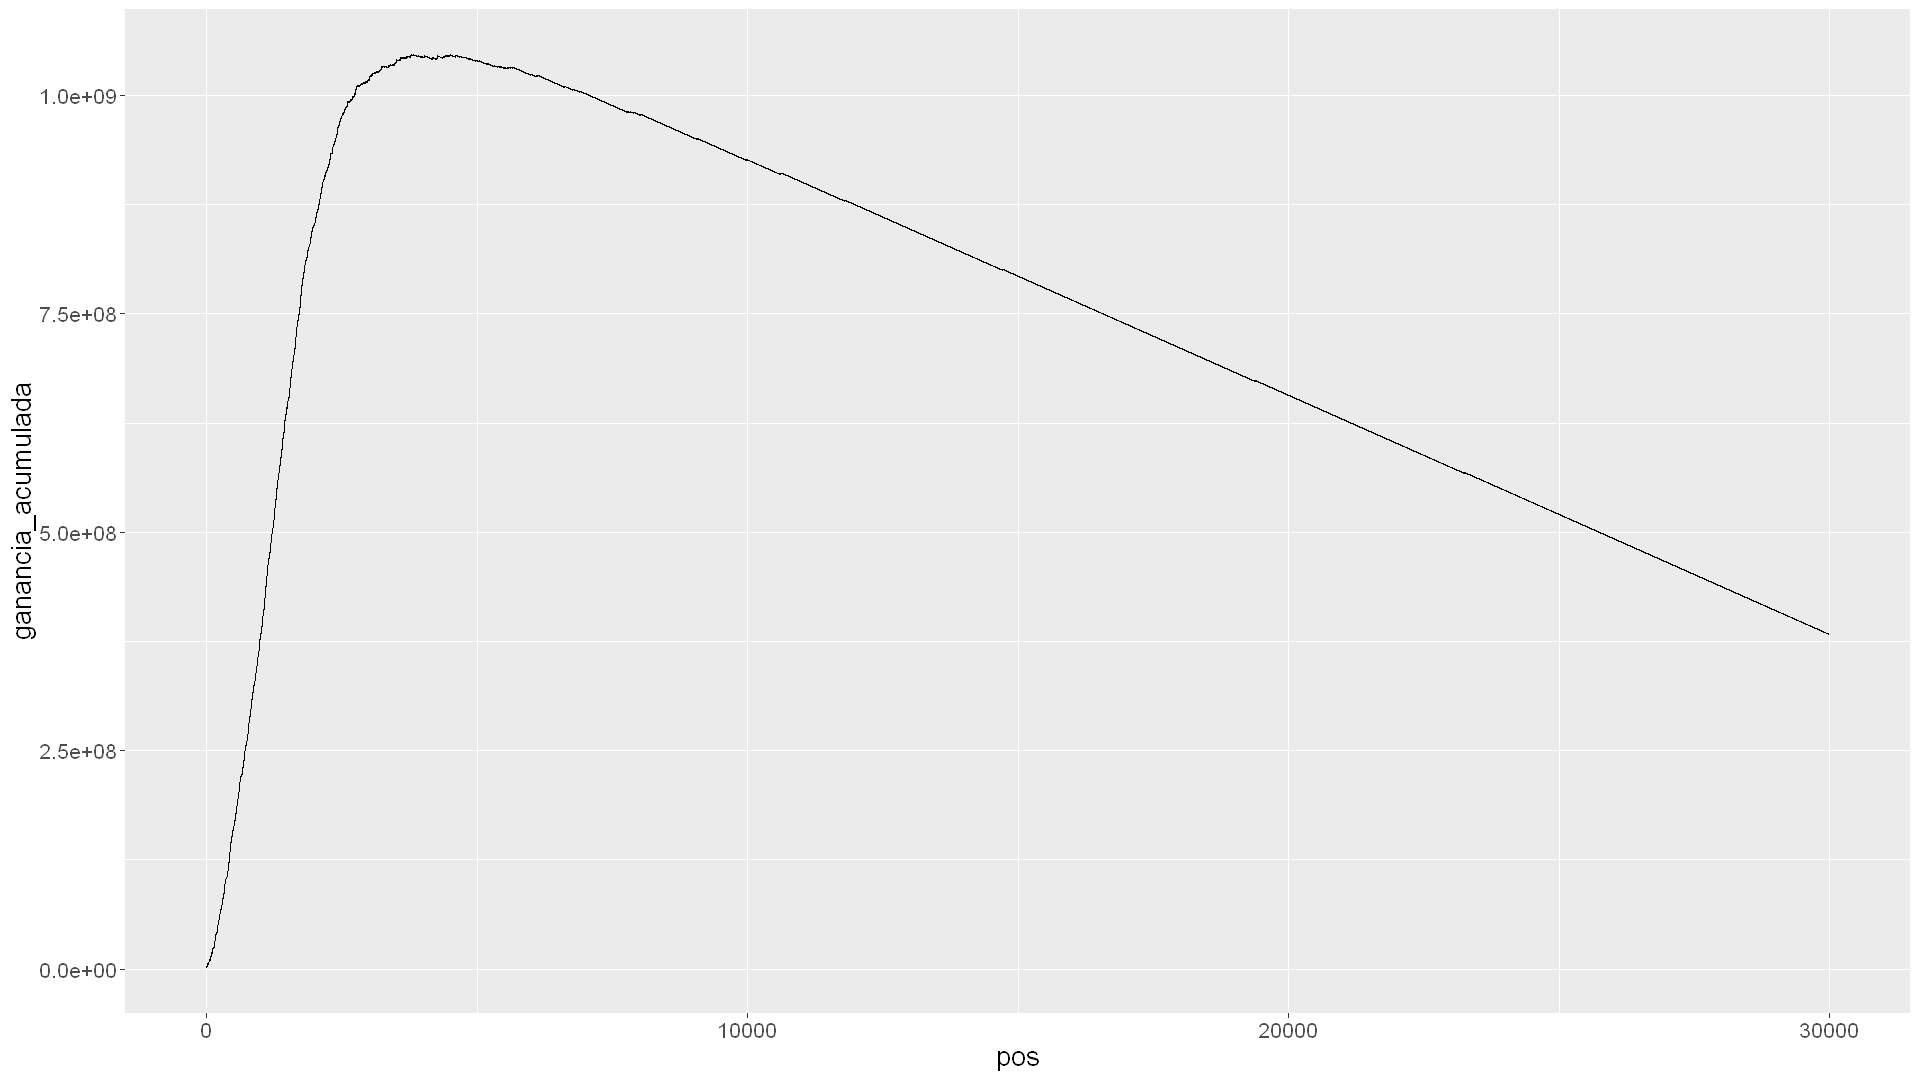

In [47]:
# observamos la curva de ganancia
gra <- ggplot(
           data= tb_prediccion[pos <= amostrar],
           aes( x= pos, y= ganancia_acumulada)
             ) + geom_line()

gra <- gra + theme(text = element_text(size = 16))

options(repr.plot.width=16, repr.plot.height=9)
print( gra )

Revisamos ganancia bajo distintos cortes

In [48]:
# inicilizo el dataset  drealidad
drealidad <- realidad_inicializar( dfuture, PARAM)

In [49]:
PARAM$cortes

[1]  4000  4500  5000  5500  6000  6500  7000  7500  8000  8500  9000  9500
[13] 10000 10500 11000 11500 12000 12500 13000 13500 14000 14500 15000 15500
[25] 16000 16500 17000 17500 18000 18500 19000

In [50]:
# genero archivos con los  "envios" mejores
# suba TODOS los archivos a Kaggle

# ordeno por probabilidad descendente
setorder(tb_prediccion, -prob)

for (envios in PARAM$cortes) {

  tb_prediccion[, Predicted := 0L] # seteo inicial a 0
  tb_prediccion[1:envios, Predicted := 1L] # marco los primeros

  res <- realidad_evaluar( drealidad, tb_prediccion)

  options(scipen = 999)
  cat( "Envios=", envios, "\t",
    " TOTAL=", res$total,
    "  Public=", res$public,
    " Private=", res$private,
    "\n",
    sep= ""
  )

}

Envios=4000	 TOTAL=1043900000  Public=1036200000 Private=1047200000
Envios=4500	 TOTAL=1045550000  Public=1039500000 Private=1048142857
Envios=5000	 TOTAL=1039500000  Public=1031891667 Private=1042760714
Envios=5500	 TOTAL=1032350000  Public=1032075000 Private=1032467857
Envios=6000	 TOTAL=1024100000  Public=1024375000 Private=1023982143
Envios=6500	 TOTAL=1012550000  Public=1009983333 Private=1013650000
Envios=7000	 TOTAL=1002100000  Public=998066667 Private=1003828571
Envios=7500	 TOTAL=988350000  Public=983766667 Private=990314286
Envios=8000	 TOTAL=977900000  Public=970933333 Private=980885714
Envios=8500	 TOTAL=965250000  Public=961216667 Private=966978571
Envios=9000	 TOTAL=951500000  Public=948108333 Private=952953571
Envios=9500	 TOTAL=938850000  Public=934175000 Private=940853571
Envios=10000	 TOTAL=926200000  Public=924183333 Private=927064286
Envios=10500	 TOTAL=912450000  Public=909975000 Private=913510714
Envios=11000	 TOTAL=900900000  Public=901083333 Private=900821429
En

In [51]:
res$total

[1] 683100000

In [52]:
write_yaml( PARAM, file="PARAM.yml")

In [53]:
format(Sys.time(), "%a %b %d %X %Y")

[1] "dom oct 11 10:08:22 2026"

Finalmente usted deberá cargar el resultado de su corrida en la Google Sheet Colaborativa,  hoja **TareaHogar04**
<br> Siéntase libre de agregar las columnas que hagan falta a la planilla

# Iteraccion del modelo con más de una semlla

In [54]:
# Iteraccion del modelo con más de una semlla
PARAM$future <- 202108
PARAM$future
# 1)500009, 500029, 500041
# 2) 141421, 500057, 500069
# 3) 314159, 271828, 161803
# 700001	700027	700057	700081	700099
# 106937	186671	309853	357587	739391
# 101537	237457	461983	718579	953761
# 110017	330017	550007	880001	990001

seeds <- c(700099,106937,186671,309853,357587,739391,
101537,237457,461983,718579,953761,
110017,330017,550007,880001,990001)

for (i in 1:length(seeds)) {
  param_final$seed <- seeds[i]
  
  # entreno LightGBM
  modelo_final <- lgb.train(
    data= dtrain_final,
    param= param_final
  )

  # aplico el modelo a los datos sin clase
  dfuture <- dataset[foto_mes %in% PARAM$future]

  # aplico el modelo a los datos nuevos
  #print(paste0("Aplicando el modelo a los datos de ", PARAM$future))
  #print(paste0("Con número de iteracciones ", i, "de", length(seeds), " y semilla ", seeds[i]))
  prediccion <- predict(
    modelo_final,
    data.matrix(dfuture[, campos_buenos, with= FALSE])
  )

  # tabla de prediccion
  tb_prediccion <- dfuture[, list(numero_de_cliente, foto_mes,clase_ternaria)]
  tb_prediccion[, prob := prediccion ]
  # Ordenar por probabilidad descendente
  setorder(tb_prediccion, -prob)

  # grabo las probabilidad del modelo
  fwrite(tb_prediccion[,list(numero_de_cliente,foto_mes,prob)], file= paste0("prediccion_agosto_20sem_", i+4, ".txt"),  sep= "\t")


}
# library(data.table)

# Definís la ruta base donde están los archivos
path <- getwd()  # o la ruta que corresponda

# Armás el vector de nombres de archivo
archivos <- file.path(path, paste0("prediccion_agosto_20sem_", 1:20, ".txt"))
archivos

# Leés todos los archivos y los combinás
dt_list <- lapply(archivos, fread, sep = "\t")
dt <- rbindlist(dt_list)

# Calculás el promedio de probabilidad por cliente
resultado <- dt[, .(probabilidad_promedio = mean(prob)), by = numero_de_cliente]

# Guardás el resultado en un archivo
fwrite(resultado, file = file.path(path, "prediccion_final_20sem.txt"), sep = "\t")


[1] 202108

[1] "c:/Users/mbustos_lightech/Documents/Master/DMEyF/datamining_ecoyfin/data/buckets/b1/exp/COMPE008_1/prediccion_agosto_20sem_1.txt" 
 [2] "c:/Users/mbustos_lightech/Documents/Master/DMEyF/datamining_ecoyfin/data/buckets/b1/exp/COMPE008_1/prediccion_agosto_20sem_2.txt" 
 [3] "c:/Users/mbustos_lightech/Documents/Master/DMEyF/datamining_ecoyfin/data/buckets/b1/exp/COMPE008_1/prediccion_agosto_20sem_3.txt" 
 [4] "c:/Users/mbustos_lightech/Documents/Master/DMEyF/datamining_ecoyfin/data/buckets/b1/exp/COMPE008_1/prediccion_agosto_20sem_4.txt" 
 [5] "c:/Users/mbustos_lightech/Documents/Master/DMEyF/datamining_ecoyfin/data/buckets/b1/exp/COMPE008_1/prediccion_agosto_20sem_5.txt" 
 [6] "c:/Users/mbustos_lightech/Documents/Master/DMEyF/datamining_ecoyfin/data/buckets/b1/exp/COMPE008_1/prediccion_agosto_20sem_6.txt" 
 [7] "c:/Users/mbustos_lightech/Documents/Master/DMEyF/datamining_ecoyfin/data/buckets/b1/exp/COMPE008_1/prediccion_agosto_20sem_7.txt" 
 [8] "c:/Users/mbustos_lightech/Documents/Master/DMEyF/datamining_ecoyfin/data/buckets/b1/exp/COMPE008_1/prediccion_agosto_20sem_8.txt" 
 [9] "c:/Users/mbustos_lightech/Documents/Master/DMEyF/datamining_ecoyfin/data/buckets/b1/exp/COMPE008_1/prediccion_agosto_20sem_9.txt" 
[10] "c:/Users/mbustos_lightech/Documents/Master/DMEyF/datamining_ecoyfin/data/buckets/b1/exp/COMPE008_1/prediccion_agosto_20sem_10.txt"
[11] "c:/Users/mbustos_lightech/Documents/Master/DMEyF/datamining_ecoyfin/data/buckets/b1/exp/COMPE008_1/prediccion_agosto_20sem_11.txt"
[12] "c:/Users/mbustos_lightech/Documents/Master/DMEyF/datamining_ecoyfin/data/buckets/b1/exp/COMPE008_1/prediccion_agosto_20sem_12.txt"
[13] "c:/Users/mbustos_lightech/Documents/Master/DMEyF/datamining_ecoyfin/data/buckets/b1/exp/COMPE008_1/prediccion_agosto_20sem_13.txt"
[14] "c:/Users/mbustos_lightech/Documents/Master/DMEyF/datamining_ecoyfin/data/buckets/b1/exp/COMPE008_1/prediccion_agosto_20sem_14.txt"
[15] "c:/Users/mbustos_lightech/Documents/Master/DMEyF/datamining_ecoyfin/data/buckets/b1/exp/COMPE008_1/prediccion_agosto_20sem_15.txt"
[16] "c:/Users/mbustos_lightech/Documents/Master/DMEyF/datamining_ecoyfin/data/buckets/b1/exp/COMPE008_1/prediccion_agosto_20sem_16.txt"
[17] "c:/Users/mbustos_lightech/Documents/Master/DMEyF/datamining_ecoyfin/data/buckets/b1/exp/COMPE008_1/prediccion_agosto_20sem_17.txt"
[18] "c:/Users/mbustos_lightech/Documents/Master/DMEyF/datamining_ecoyfin/data/buckets/b1/exp/COMPE008_1/prediccion_agosto_20sem_18.txt"
[19] "c:/Users/mbustos_lightech/Documents/Master/DMEyF/datamining_ecoyfin/data/buckets/b1/exp/COMPE008_1/prediccion_agosto_20sem_19.txt"
[20] "c:/Users/mbustos_lightech/Documents/Master/DMEyF/datamining_ecoyfin/data/buckets/b1/exp/COMPE008_1/prediccion_agosto_20sem_20.txt"